# Demo: two cubes that look the same

A cube is pushed across the floor with the same impulse in every clip. Its mass m and friction μ never show in a single frame; they only change how it moves.
This notebook takes two test clips with almost the same friction and masses of about 0.6 kg and 1.8 kg, shows that their first frames are pixel-identical, and then asks frozen V-JEPA 2 features to recover m and μ from frame 0 only, from the whole clip, and from the clip plus a realistic touch signal.

In [1]:
import hashlib, os, sys
ROOT = os.environ.get("PHYSPROBE_ROOT", os.path.abspath(".."))
sys.path.insert(0, ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from physprobe import io
from physprobe.probes import run as pr          # the canonical probe protocol

DS = "push"
meta = io.load_meta(DS)
by_id = {r["id"]: r for r in meta}
splits, _ = pr.make_splits(meta, 0)              # io.split_ids(meta, 0) minus ok=False rows (none here)
print({s: len(v) for s, v in splits.items()})

{'train': 1400, 'val': 300, 'test': 300}


## 1. The two clips

Selection rule, fixed before any probe is fitted: both clips from the **test** split, |μ_A − μ_B| < 0.05, and the pair closest to m = 0.6 kg and 1.8 kg in log mass.

In [2]:
test = [by_id[i] for i in splits["test"]]
_, A, B = min((abs(np.log(a["m"] / 0.6)) + abs(np.log(b["m"] / 1.8)), a["id"], b["id"])
              for a in test for b in test if abs(a["mu"] - b["mu"]) < 0.05)
for name, i in (("A", A), ("B", B)):
    r = by_id[i]
    print(f"cube {name}: id {i}, split {r['split']}, m = {r['m']:.3f} kg, mu = {r['mu']:.3f}, "
          f"v0 = J/m = {r['v0']:.3f} m/s, stops at {r['t_stop_s']:.2f} s, moves {r['moved_px']:.0f} px")
print(f"|mu_A - mu_B| = {abs(by_id[A]['mu'] - by_id[B]['mu']):.3f}")

cube A: id 000658, split test, m = 0.605 kg, mu = 0.212, v0 = J/m = 1.654 m/s, stops at 0.80 s, moves 114 px
cube B: id 001077, split test, m = 1.798 kg, mu = 0.233, v0 = J/m = 0.556 m/s, stops at 0.24 s, moves 12 px
|mu_A - mu_B| = 0.022


Frame 0 is rendered at rest, before the push, so it is the same image for every clip.

000658: sha1(frame 0)[:16] = c7c04432a20d0a35  (meta: c7c04432a20d0a35)
001077: sha1(frame 0)[:16] = c7c04432a20d0a35  (meta: c7c04432a20d0a35)
max |frame0_A - frame0_B| = 0


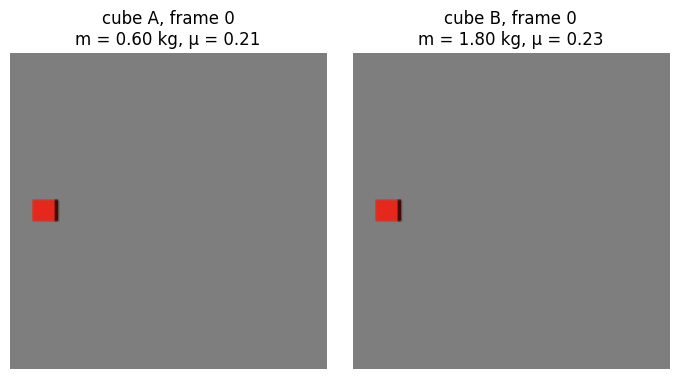

In [3]:
clip = {i: io.load_clip(DS, i) for i in (A, B)}
f0 = {i: np.asarray(clip[i][0]) for i in (A, B)}
for i in (A, B):
    print(f"{i}: sha1(frame 0)[:16] = {hashlib.sha1(f0[i].tobytes()).hexdigest()[:16]}  (meta: {by_id[i]['frame0_hash']})")
print("max |frame0_A - frame0_B| =", int(np.abs(f0[A].astype(int) - f0[B].astype(int)).max()))

fig, ax = plt.subplots(1, 2, figsize=(7, 3.7))
for a, i, name in zip(ax, (A, B), "AB"):
    a.imshow(f0[i]); a.set_axis_off()
    a.set_title(f"cube {name}, frame 0\nm = {by_id[i]['m']:.2f} kg, μ = {by_id[i]['mu']:.2f}")
plt.tight_layout(); plt.show()

Later frames (64 fps, 1 s per clip; the strip around the cube's path is shown, dashed line = start position of the cube centre). The light cube A is still sliding at frame 32; the heavy cube B has stopped before frame 16.

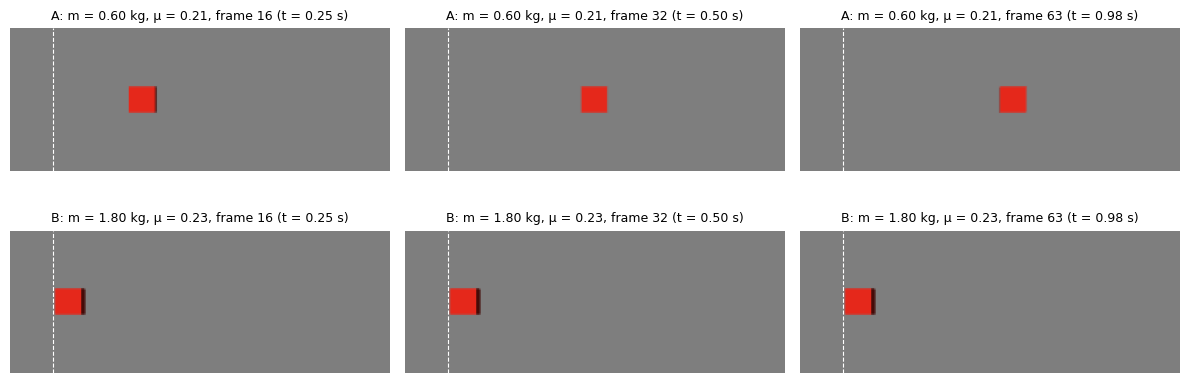

In [4]:
u0 = io.load_dataset_json(DS)["camera"]["origin_px_com"][0]    # pixel column of the cube centre at x = 0
FRAMES, ROWS = (16, 32, 63), slice(80, 176)
fig, ax = plt.subplots(2, 3, figsize=(12, 4.6))
for row, i, name in zip(ax, (A, B), "AB"):
    for a, k in zip(row, FRAMES):
        a.imshow(clip[i][k][ROWS]); a.axvline(u0, ls="--", c="w", lw=0.8); a.set_axis_off()
        a.set_title(f"{name}: m = {by_id[i]['m']:.2f} kg, μ = {by_id[i]['mu']:.2f}, frame {k} (t = {k / 64:.2f} s)",
                    fontsize=9)
plt.tight_layout(); plt.show()

Ground truth from the simulator: cube position x(t), floor normal force fn(t) = m·g and tangential force ft(t) = μ·m·g while sliding, 0 after the stop. The raw forces are an oracle for (m, μ); the probe below only sees the *realistic* touch block (each channel floored, divided by its clip maximum, plus noise, and a binary slip flag), so the absolute force scale is gone.

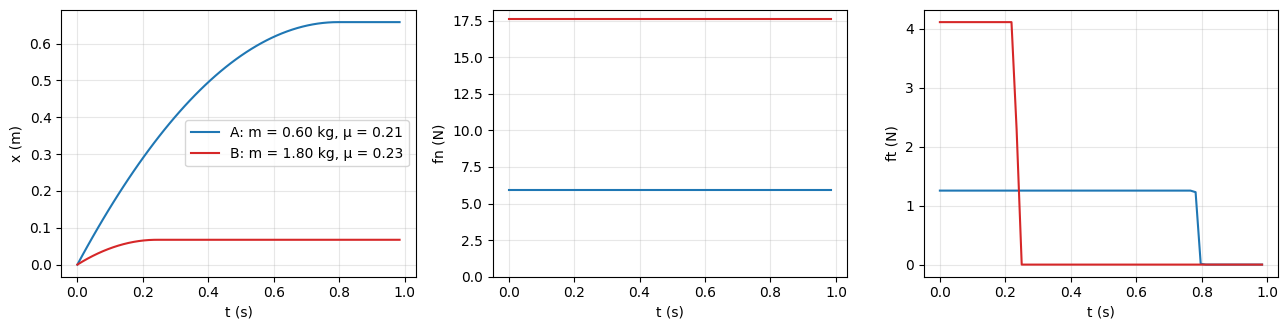

In [5]:
t = np.arange(64) / 64
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for i, name, c in ((A, "A", "C0"), (B, "B", "C3")):
    st, ct = io.load_state(DS, i), io.load_contact(DS, i)
    lab = f"{name}: m = {by_id[i]['m']:.2f} kg, μ = {by_id[i]['mu']:.2f}"
    ax[0].plot(t, st[:, 0], c, label=lab)
    ax[1].plot(t, ct[:, 0], c, label=lab)
    ax[2].plot(t, ct[:, 1], c, label=lab)
for a, yl in zip(ax, ("x (m)", "fn (N)", "ft (N)")):
    a.set_xlabel("t (s)"); a.set_ylabel(yl); a.grid(alpha=0.3)
ax[0].legend(); ax[1].set_ylim(0, None); plt.tight_layout(); plt.show()

## 2. Probe demo

Canonical protocol, reusing the functions of `physprobe/probes/run.py` (seed 0 split): z-score on train (PCA to 256 if D > 2048, which none of these inputs needs), ridge with α chosen by 5-fold CV on train only. Three inputs, all frozen V-JEPA 2 ViT-L:

- **frame 0**: `vjepa2_l/static`, features of frame 0 alone;
- **clip**: `vjepa2_l/clip_mean_L16`, the whole 64-frame clip, block 16, mean over tokens;
- **clip + touch**: `vjepa2_l/clip_mean_L16 + contact/realistic`, each block z-scored on train and scaled by 1/√D, then concatenated.

Each probe is fitted on the 1400 training clips; we report its predictions for cubes A and B and, as a check, its R² on all 300 test clips next to the value stored in `results/push/probes.csv`.

In [6]:
tv = {t: pr.target_values(meta, t) for t in ("log_m", "mu")}     # log_m = ln m
INPUTS = {"frame 0": "vjepa2_l/static",
          "clip": "vjepa2_l/clip_mean_L16",
          "clip + touch": "vjepa2_l/clip_mean_L16+contact/realistic"}

def probe(spec, target):
    ids = {"train": splits["train"], "test": splits["test"], "demo": [A, B]}
    blocks = [pr.Block(DS, *b.split("/")) for b in spec.split("+")]
    parts = [pr.impute_nans([b.take(ids[s]) for s in ids], spec) for b in blocks]
    combo = len(blocks) > 1
    X = pr.scale_blocks(parts) if combo else parts[0]             # combo: per-block z-score, x 1/sqrt(D)
    Ptr, Pte, Pdemo, _ = pr.preprocess(*X, seed=0, prescaled=combo)  # z-score on train; PCA-256 if D > 2048
    y = {s: np.array([tv[target][i] for i in ids[s]]) for s in ids}
    ridge = pr.fit_ridge(Ptr, y["train"])                           # RidgeCV(logspace(-3, 6, 28), cv=5) on train
    return ridge.predict(Pdemo), r2_score(y["test"], ridge.predict(Pte))

csv = pd.read_csv(os.path.join(ROOT, "results", DS, "probes.csv"))
ref = csv[(csv.probe == "ridge") & (csv.seed == 0)].set_index(["inputs", "target"]).r2
ytr = {t: np.array([tv[t][i] for i in splits["train"]]) for t in tv}
rows = [{"input": "truth", "m_A (kg)": by_id[A]["m"], "μ_A": by_id[A]["mu"], "m_B (kg)": by_id[B]["m"], "μ_B": by_id[B]["mu"]},
        {"input": "train mean", "m_A (kg)": np.exp(ytr["log_m"].mean()), "μ_A": ytr["mu"].mean(),
         "m_B (kg)": np.exp(ytr["log_m"].mean()), "μ_B": ytr["mu"].mean()}]
for name, spec in INPUTS.items():
    (lm, r2_lm), (mu, r2_mu) = probe(spec, "log_m"), probe(spec, "mu")
    rows.append({"input": name, "m_A (kg)": np.exp(lm[0]), "μ_A": mu[0], "m_B (kg)": np.exp(lm[1]), "μ_B": mu[1],
                 "test R² ln m": r2_lm, "test R² μ": r2_mu,
                 "max |ΔR²| vs probes.csv": max(abs(r2_lm - ref[(spec, "log_m")]), abs(r2_mu - ref[(spec, "mu")]))})
table = pd.DataFrame(rows).set_index("input")
print(table.to_string(float_format="%.3f", na_rep=""))

              m_A (kg)   μ_A  m_B (kg)   μ_B  test R² ln m  test R² μ  max |ΔR²| vs probes.csv
input                                                                                         
truth            0.605 0.212     1.798 0.233                                                  
train mean       0.989 0.499     0.989 0.499                                                  
frame 0          0.989 0.499     0.989 0.499        -0.018     -0.004                    0.000
clip             0.610 0.217     1.761 0.237         0.997      0.975                    0.000
clip + touch     0.627 0.193     1.767 0.224         0.997      0.983                    0.000


**Conclusion.** The two first frames are pixel-identical, so the frame-0 probe can only return the training mean for both cubes, while the clip probe recovers both masses within about 2 % and both frictions within 0.01, and adding the realistic touch signal changes these predictions by less than 0.03 kg and 0.03 in μ.

Provenance. The notebook was executed on the compute clone, whose HEAD is fce21d1 with the rerun's `results/` files not yet committed there (hence `-dirty`). Its code and `results/` are byte-identical to commit 40be2f9, which differs only in documentation and `scripts/reproduce.sh`.

In [7]:
print("git commit (io.git_commit):", io.git_commit())
for spec in ("vjepa2_l/static", "vjepa2_l/clip_mean_L16", "contact/realistic"):
    info = io.load_features(DS, *spec.split("/"))[2]
    print(f"{spec:24s} revision={info.get('revision')}  hf_id={info.get('hf_id')}  "
          f"extracted at git {info.get('git_commit')}  code_hash={info.get('code_hash')}  created={info.get('created')}")

git commit (io.git_commit): fce21d1-dirty
vjepa2_l/static          revision=b3c1679b7c34d3255ef3547f27c7b226aefab26f  hf_id=facebook/vjepa2-vitl-fpc64-256  extracted at git fce21d1  code_hash=e86e617ab2fd  created=2026-10-22T22:20:53+00:00
vjepa2_l/clip_mean_L16   revision=b3c1679b7c34d3255ef3547f27c7b226aefab26f  hf_id=facebook/vjepa2-vitl-fpc64-256  extracted at git fce21d1  code_hash=e86e617ab2fd  created=2026-10-22T22:24:21+00:00
contact/realistic        revision=None  hf_id=None  extracted at git fce21d1f78ffedc5acdeb0a1e1ae54c654c780a2  code_hash=None  created=2026-10-22T22:49:31+00:00
